# 수율 이상 RCA — 제품 23 · 배치 889

| 항목 | 내용 |
|---|---|
| 판정 | 수율 이상(경고) |
| 절차 | 상세 노트북 `notebooks/RCA_Lek_yield_deviation.ipynb`(배치 790)와 같은 7단계: 규격 → 5W1H → 발생 보고서 → 6M → 가설별 5 Why → 통계 검정 → RCA 보고서 |
| 코드 | 모든 계산은 같은 폴더의 `rca_core.py` 에 있고, 이 노트북은 결과와 해석을 보여줍니다 |
| 실행 | 저장소 루트에서 `uv sync` → 이 폴더에서 노트북 실행 |
| 표시 규칙 | 5 Why 근거 [데이터] / [데이터+추정] / [추정] · 데이터에 없는 보고서 항목은 [가상] |

In [1]:
from rca_core import RCA
ctx = RCA(889)
ctx.show_overview()

| 항목 | 내용 |
|---|---|
| 대상 | 제품 23 (함량 20 mg) · 배치 889 |
| 판정 | **수율 이상(경고)** — 수율 96.50% (경고 하한 96.89%, 일탈 하한 96.12%) |
| 생산 일시 | 2021-02-05 13:49 ~ 2021-02-09 01:27 (날짜 해석: 원본(일월연도)) |
| 비교 기준 | 제품 23의 다른 배치 186개 (평균 수율 98.38%) |
| 손실 추적 가능 비율 | 40% (타정기 폐기 기록 ÷ 손실) |

> ⚠ **데이터 RCA 범위 주의** — 손실의 40%만 타정기 폐기 기록으로 추적됩니다. 이 노트북의 결론은 기록된 손실에 대한 것이며, 나머지는 현장 기록(청소·수작업 폐기·집진·샘플링)으로 확인해야 합니다.

---
## 1. STEP 1 — 수율 규격과 판정

제품별 과거 수율로 세운 통계적 관리 기준입니다. 기준선 = 중앙값, σ̂ = 1.4826 × MAD.
**경고 하한(중앙값 − 2σ̂) 미만 = 수율 이상**, **일탈 하한(중앙값 − 3σ̂) 미만 또는 100% 초과 = 수율 일탈**.

**제품 23 수율 규격** — 기준선(중앙값) 98.44%, σ̂ = 0.77%p → 경고 하한 96.89%, 일탈 하한 96.12%, 상한 100.0%  
제품 23 배치 187개 중: 정상 178개, 수율 이상(경고) 6개, 수율 일탈(하한 미달) 3개

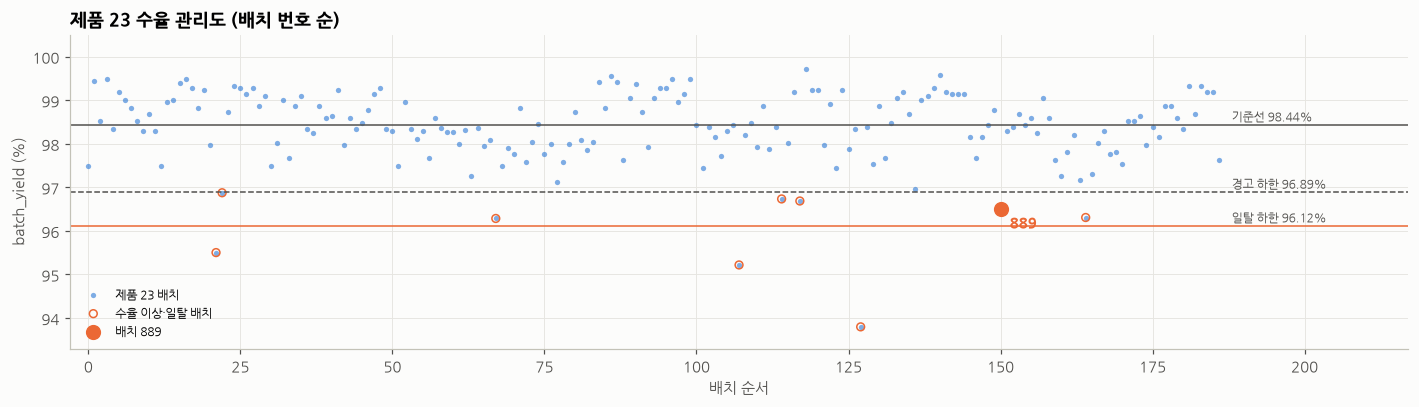

In [2]:
ctx.show_spec()

---
## 2. STEP 2 — 5W1H 문제 정의

### 2.1 생산 과정 — 대상 배치와 대표 정상 배치의 10초 시계열

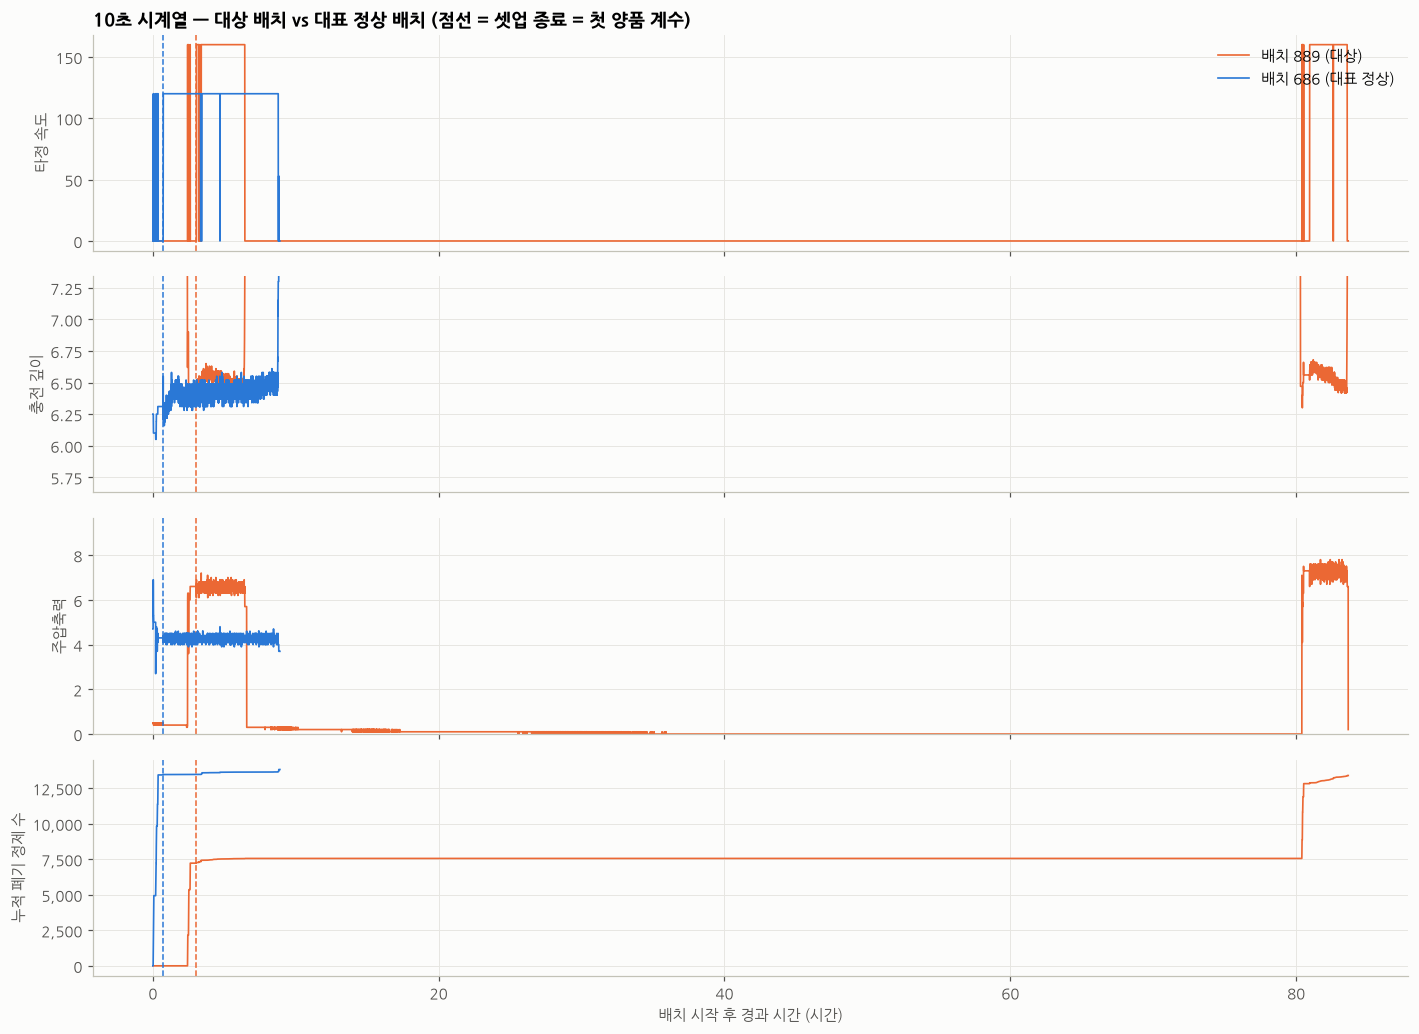

> **관찰** — 셋업 183분 (제품 중앙값 48분, 그중 정지 180분), 본생산 중 정지 4483분 (중앙값 15분), 1분 이상 정지 10회 (중앙값 2회). 대표 정상 배치는 686입니다(캠페인 첫 배치가 아니고 셋업·정지 시간이 중앙값 이하인 배치 중 수율이 중앙값에 가장 가까운 배치).

In [3]:
ctx.show_trace()

### 2.2 손실 분해

손실 = 셋업 폐기 + 본생산 폐기 + 타정 이후 공정 손실 + 미기록 손실(타정기 카운터 밖 손실). '중앙값 대비'는 같은 제품 다른 배치의 중앙값과의 차이입니다.

In [4]:
ctx.show_loss()

,대상 배치 (정),손실 중 비중,제품 중앙값 (정),중앙값 대비
셋업 폐기,"7,272",22%,"6,780",+492
본생산 폐기,"6,119",18%,280,"+5,838"
타정 이후 공정 손실,"1,757",5%,0,"+1,757"
미기록 손실,"18,491",55%,"3,954","+14,537"
손실 합계,"33,638",100%,"14,995","+18,643"


> **해석** — 평소(제품 중앙값)보다 가장 많이 늘어난 손실은 **미기록 손실**(+14,537정)입니다. 셋업 폐기 +492정. 본생산 폐기 +5,838정. 타정 이후 공정 손실 +1,757정. 미기록 손실은 타정기 카운터 밖 손실이라 데이터로 원인을 좇을 수 없습니다.

### 2.3 5W1H

In [5]:
ctx.show_5w1h()

| 항목 | 내용 |
|---|---|
| **What (무엇이)** | 제품 23(함량 20 mg) 배치 889의 배치 수율이 **96.50%**로 경고 하한 96.89%를 0.40%p 밑돌았다 (참조 평균 대비 -1.89%p). |
| **When (언제)** | 2021-02-05 13:49 ~ 2021-02-09 01:27. 캠페인 170의 첫 배치(제품 교체 직후). 셋업 13:49~16:52. |
| **Where (어디서)** | 타정 공정 + 타정 이후 공정(타정 수율 96.68% → 배치 수율 96.50%). 손실 위치: 셋업 22% · 본생산 18% · 이후 공정 5% · 미기록 55%. |
| **Who (누가)** | 발견·보고: 공정 엔지니어 [가상]. 관련: 13시에 셋업을 시작한 작업조 (데이터에 인력 정보 없음). |
| **Why (왜)** | **미확정 — RCA로 규명.** 관찰: 셋업 183분(중앙값 48분), 본생산 중 정지 4483분(중앙값 15분). |
| **How (어떻게·얼마나)** | 이론 960,000정 중 양품 926,362정, 손실 **33,638정** = 셋업 폐기 7,272 + 본생산 폐기 6,119 + 이후 공정 1,757 + 미기록 18,491. |

---
## 3. STEP 3 — 수율 이상 발생 보고서

팀 양식의 발생보고서 항목을 따릅니다. 데이터에 없는 항목(보고자, 발견 시각, 초기 조치)은 **[가상]** 예시입니다.

In [6]:
ctx.show_incident_report()

---
## 4. STEP 4 — 6M 원인 후보

6M 관점별 1~3개, 총 14개 가설을 같은 기준으로 봅니다. 대상 배치의 지표가 같은 제품 참조 배치와 비교해
가설 방향으로 **상위·하위 5% 안**이면(예/아니오 지표는 '해당'이면) 관찰된 것으로 보고 5 Why로 넘깁니다.
관찰되지 않은 가설은 이 배치를 설명할 수 없으므로 Why 1에서 종결합니다.

,6M,원인 후보,지표,대상 값,참조,극단 백분위,관찰 판정
id,,,,,,,
MAN-1,인력,야간 시간대 셋업 착수 (숙련 인력·지원 부족),배치 시작 22~06시,아니오,참조 중 36%,—,해당 없음
MAN-2,인력,주말 생산 (인력 축소 운영),주말 생산 여부,예,참조 중 3%,—,해당
MAN-3,인력,운전 설정값 이탈 (설정 입력·레시피 선택 오류),속도·주압축력 설정 이탈(중앙값 대비 %),33.35,중앙값 13.64,8.6%,해당 없음
MAC-1,설비,본생산 중 장시간 정지·재시작 반복,본생산 중 정지 시간(분),"4,483",중앙값 15.25,0.5%,이상 관찰
MAC-2,설비,주압축력 변동 (압축부 불안정),주압축력 표준편차,0.39,중앙값 0.11,3.7%,이상 관찰
MAC-3,설비,정제 배출력 과다 (금형·펀치 마찰),배출력 최댓값,436,중앙값 235,1.6%,이상 관찰
MAT-1,자재,API 입도가 미세한 로트 (흐름성 저하),API 입도 D90(μm),133,중앙값 147,26.7%,해당 없음
MAT-2,자재,API 수분 과다 (뭉침·부착),API 수분(%),0.94,중앙값 1.22,85.0%,해당 없음
MET-1,방법,셋업 장기화,셋업 시간(분),183,중앙값 48.50,1.1%,이상 관찰


> **관찰된 가설 6개**: MAN-2 주말 생산, MAC-1 본생산 중 장시간 정지, MAC-2 주압축력 변동, MAC-3 배출력 과다, MET-1 셋업 장기화, ENV-1 생산 계절 온·습도  
> **종결 8개**: MAN-1 야간 셋업 착수, MAN-3 운전 설정값 이탈, MAT-1 API 입도 미세, MAT-2 API 수분 과다, MET-2 충전 조건 반복 변경, MET-3 셋업 직후 조건 재조정, MEA-1 셋업 중 SREL 과변동, MEA-2 정제 무게 편차

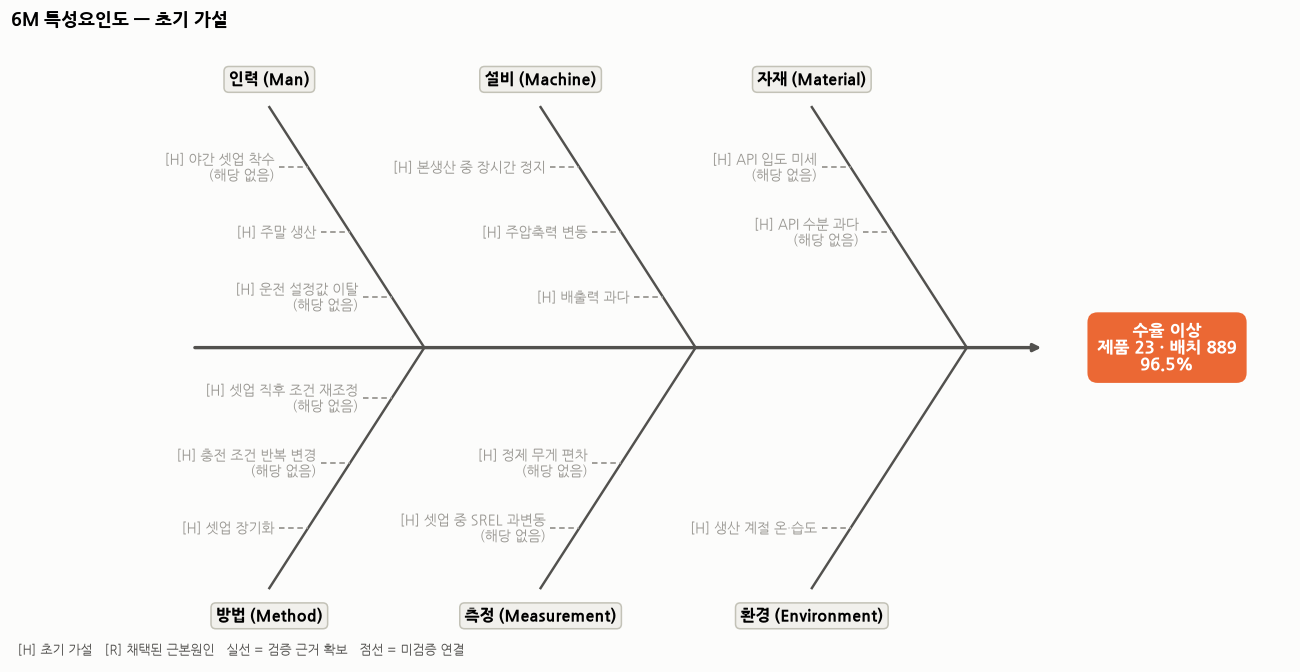

In [7]:
ctx.show_hypotheses()
ctx.draw_fishbone(after=False)

---
## 5. STEP 5 — 가설별 5 Why

- Why 1 질문은 모든 경로에 공통("왜 수율이 떨어졌나?"), **Why 1의 답 = 가설**입니다. 가설이 작용한 손실 구간은 '작용 위치'로 따로 적습니다.
- 각 답의 근거: **[데이터]** 데이터로 관찰한 사실 · **[데이터+추정]** 사실은 관찰되지만 이유·방향은 해석 · **[추정]** 데이터에 근거 없음(현장 확인 필요).
- 같은 Why 5(근본원인)에 도달한 경로는 하나의 근본원인 후보(RC)로 묶습니다.

In [8]:
ctx.show_five_why()

#### RC-MET-A (방법) 로 이어지는 경로

#### RC-MAC (설비) 로 이어지는 경로

#### RC-TOOL (설비) 로 이어지는 경로

#### RC-MAN-A (인력) 로 이어지는 경로

#### RC-ENV (환경) 로 이어지는 경로

### 5.1 근본원인 후보 통합

In [9]:
ctx.show_rc_table()

,관점,근본원인 후보 (Why 5),연결 가설,가설 간 관계,"Why 1~5 근거 (데=데이터, 데+=데이터+추정, 추=추정)"
RC,,,,,
RC-MET-A,방법,제품별로 검증된 초기 셋업 설정값(충전 깊이·압축력 레시피)이 정립되어 있지 않다.,MET-1,단일 경로,MET-1: 데·데+·데+·추·추
RC-MAC,설비,재시작 후 공정 조건 안정화 확인 절차와 압축부 상태 점검·경보 기준이 없다.,"MAC-1, MAC-2",MAC-2 → MAC-1,MAC-1: 데·데+·데+·추·추 / MAC-2: 데·추·추·추·추
RC-TOOL,설비,금형·펀치 상태 점검·교체 기준(사용 횟수·배출력 경보)이 없다.,MAC-3,단일 경로,MAC-3: 데·추·추·추·추
RC-MAN-A,인력,야간·주말 셋업과 이상 대응에 숙련자 배치·지원 요청(에스컬레이션) 기준이 없다.,MAN-2,단일 경로,MAN-2: 데·추·추·추·추
RC-ENV,환경,계절별 작업장 온·습도 관리 기준(경보·공조 조정 절차)이 없다.,ENV-1,단일 경로,ENV-1: 데·추·추·추·추


---
## 6. STEP 6 — 통계 검정

| 단계 | 질문 | 방법 | 판정 |
|---|---|---|---|
| ① 대상 배치 해당성 | 이 조건이 대상 배치에 실제로 있었나? | 경험적 p (참조 중 대상만큼 극단인 비율) | p < 0.05 또는 '해당' |
| ② 수율 연관성 | 평소에도 이 조건이 수율 저하와 함께 나타나나? | 스피어만 ρ / 맨-휘트니 U (**양측**), Holm 보정 | Holm p < 0.05 **이고 방향이 가설과 일치** → 채택 |
| ② 보류 규칙 | 비교할 비슷한 사례가 있나? 지표가 조건 자체를 재나? | 참조 중 대상 수준의 절반 이상 극단인 배치 수 · 대리 지표 여부 | 비슷한 사례 3개 미만이고 유의하지 않으면 「보류(참조 부족)」, 대리 지표(계절)는 유의해도 「보류(대리 지표)」 |
| ③ 근본원인 확인 | 같은 현상을 두 번 센 것은 아닌가? | 합류 고리 상관, RC 간 상관, 편 스피어만(다른 RC 통제) | 독립 효과가 유의하고 방향 일치 → RC 채택 |

검정 방법별 목적과 필요성은 팀 문서 「RCA 가설 통계 검정 방법 정리」를 참고하세요.

,RC,6M,검증 지표,① 극단 p,① 통과,② 효과,방향 일치,② n,비슷한 수준 참조 수,② p (양측),② p (Holm),판정
가설,,,,,,,,,,,,
MAN-2,RC-MAN-A,인력,주말 생산 여부,해당(예),True,클리프 δ = -0.77,True,5 vs 181,5,0.0034,0.0053,채택
MAC-1,RC-MAC,설비,본생산 중 정지 시간(분),0.005,True,스피어만 ρ = -0.27,True,186,5,0.00024,0.00073,채택
MAC-2,RC-MAC,설비,주압축력 표준편차,0.037,True,스피어만 ρ = -0.31,True,186,14,1.7e-05,6.6e-05,채택
MAC-3,RC-TOOL,설비,배출력 최댓값,0.016,True,스피어만 ρ = -0.22,True,186,27,0.0027,0.0053,채택
MET-1,RC-MET-A,방법,셋업 시간(분),0.011,True,스피어만 ρ = -0.41,True,186,1,4.6e-09,2.8e-08,채택
ENV-1,RC-ENV,환경,대상 배치와 같은 계절 생산,해당(예),True,클리프 δ = -0.49,True,46 vs 140,46,6.2e-07,3.1e-06,보류(대리 지표)


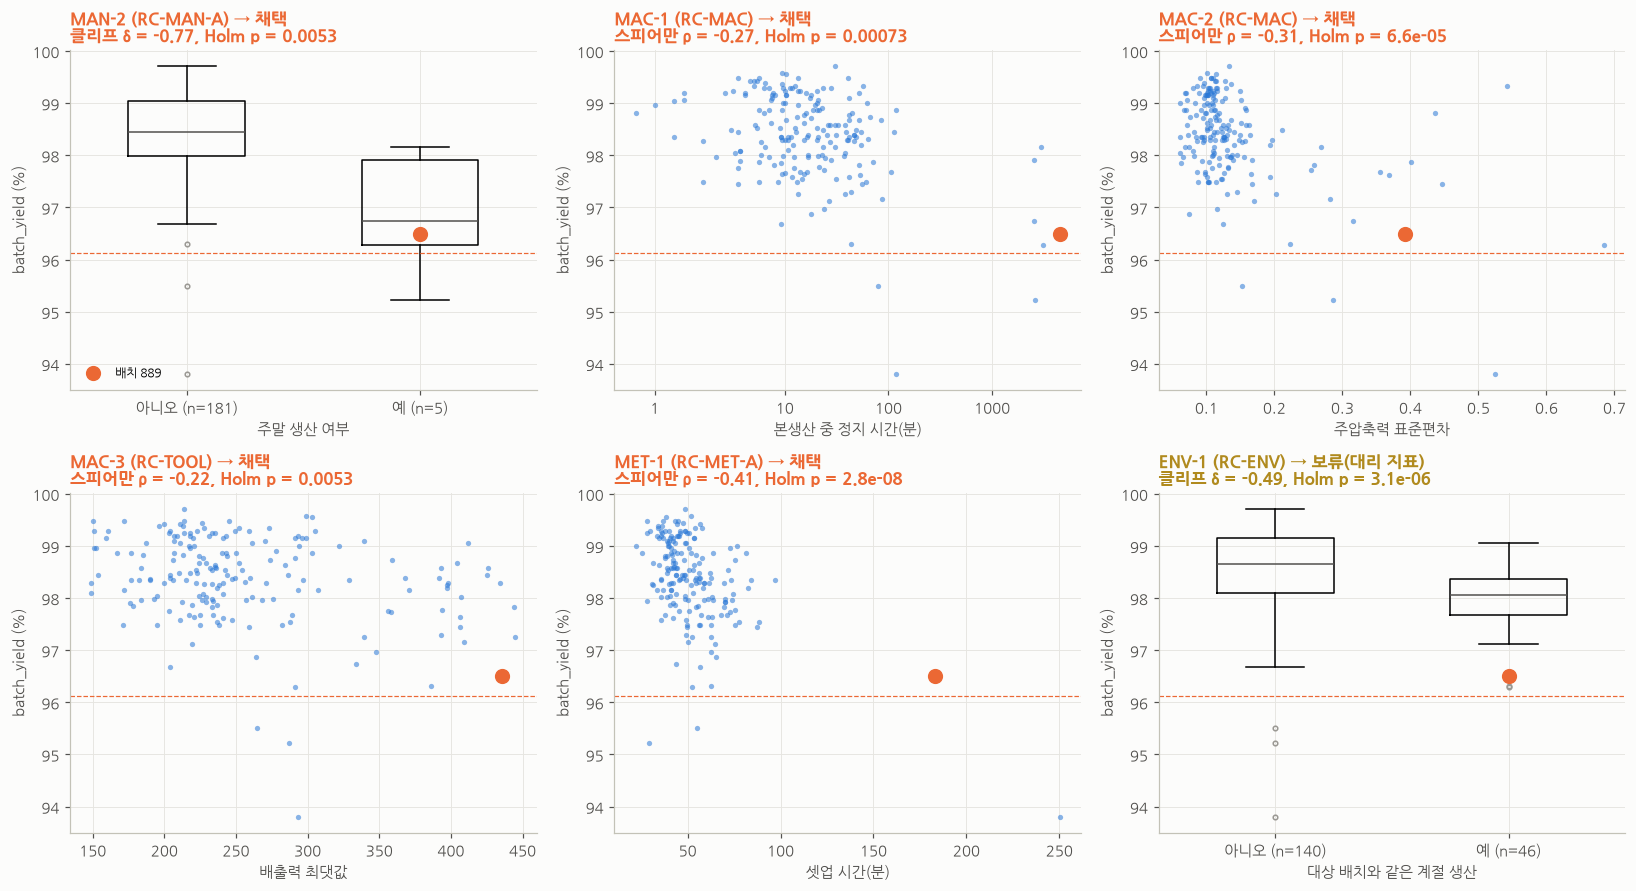

> **해석**
>
> - **채택** (5개: MAN-2 주말 생산, MAC-1 본생산 중 장시간 정지, MAC-2 주압축력 변동, MAC-3 배출력 과다, MET-1 셋업 장기화) — 대상 배치 말고 다른 배치들에서도 이 조건이 수율 저하와 함께 나타납니다.
> - **보류(대리 지표)** (1개: ENV-1 생산 계절 온·습도) — 평소에도 수율과 연관되지만 지표가 가설의 조건 자체(온·습도)를 재지 않는 대리 지표라 근본원인으로 채택하지 않습니다 → 작업장 온·습도 기록으로 확인.

In [10]:
ctx.show_tests()

### 6.1 근본원인 확인과 최종 판정

In [11]:
ctx.show_stage3()

RC,구분,확인 내용,방법,통계량,p,결과
RC-MAC,(a) 합류 고리,MAC-2 주압축력 변동 ↑ ↔ MAC-1 본생산 중 장시간 정지 ↑,스피어만 ρ (양측),+0.34,2.3e-06,연관 있음
RC-MET-A·RC-MAC,(b) 독립성,MET-1 ↔ MAC-1,스피어만 ρ (양측),+0.00,0.97,독립
RC-MET-A·RC-TOOL,(b) 독립성,MET-1 ↔ MAC-3,스피어만 ρ (양측),+0.07,0.37,독립
RC-MET-A·RC-MAN-A,(b) 독립성,MET-1 ↔ MAN-2,스피어만 ρ (양측),-0.04,0.63,독립
RC-MAC·RC-TOOL,(b) 독립성,MAC-1 ↔ MAC-3,스피어만 ρ (양측),+0.31,1.5e-05,연관
RC-MAC·RC-MAN-A,(b) 독립성,MAC-1 ↔ MAN-2,스피어만 ρ (양측),+0.28,0.00011,연관
RC-TOOL·RC-MAN-A,(b) 독립성,MAC-3 ↔ MAN-2,스피어만 ρ (양측),+0.11,0.14,독립
RC-MET-A,(b) 독립 효과,"MET-1 → 수율 | prod_stop_min, ejection_max, is_weekend 통제",편 스피어만 ρ (양측),-0.43,7.9e-10,독립 효과 있음
RC-MAC,(b) 독립 효과,"MAC-1 → 수율 | setup_min, ejection_max, is_weekend 통제",편 스피어만 ρ (양측),-0.19,0.009,독립 효과 있음
RC-TOOL,(b) 독립 효과,"MAC-3 → 수율 | setup_min, prod_stop_min, is_weekend 통제",편 스피어만 ρ (양측),-0.13,0.08,독립 효과 확인 안 됨


,관점,근본원인 후보,연결 가설 (판정),③ 독립 효과,RC 판정,보고서 번호
RC,,,,,,
RC-MET-A,방법,제품별로 검증된 초기 셋업 설정값(충전 깊이·압축력 레시피)이 정립되어 있지 않다.,MET-1(채택),"편 ρ = -0.43, p = 7.9e-10",채택,R1
RC-MAC,설비,재시작 후 공정 조건 안정화 확인 절차와 압축부 상태 점검·경보 기준이 없다.,"MAC-1(채택), MAC-2(채택)","편 ρ = -0.19, p = 0.009",채택,R2
RC-TOOL,설비,금형·펀치 상태 점검·교체 기준(사용 횟수·배출력 경보)이 없다.,MAC-3(채택),"편 ρ = -0.13, p = 0.08",기각(독립 효과 없음),—
RC-MAN-A,인력,야간·주말 셋업과 이상 대응에 숙련자 배치·지원 요청(에스컬레이션) 기준이 없다.,MAN-2(채택),"편 ρ = -0.19, p = 0.012",채택,R3
RC-ENV,환경,계절별 작업장 온·습도 관리 기준(경보·공조 조정 절차)이 없다.,ENV-1(보류(대리 지표)),—,보류(현장 확인),—


> **채택 근본원인**: **R1 [방법]** 제품별로 검증된 초기 셋업 설정값(충전 깊이·압축력 레시피)이 정립되어 있지 않다. / **R2 [설비]** 재시작 후 공정 조건 안정화 확인 절차와 압축부 상태 점검·경보 기준이 없다. / **R3 [인력]** 야간·주말 셋업과 이상 대응에 숙련자 배치·지원 요청(에스컬레이션) 기준이 없다.
>
> **보류(현장 확인)**: RC-ENV (계절별 작업장 온·습도 관리 기준(경보·공조 조정 절차)이 없다.) — 대리 지표(계절)만으로는 판단할 수 없음 → 작업장 온·습도 기록 확인
>
> **가설은 채택됐지만 근본원인으로는 기각**: RC-TOOL — 다른 채택 근본원인을 통제하면 수율 효과가 남지 않아, 같은 현상을 중복으로 센 것으로 봅니다.

---
## 7. STEP 7 — RCA 결과 정리

### 7.1 근본원인 해소 시 추정 수율 (단순 산술)

In [12]:
ctx.show_whatif()

시나리오,양품 (정),수율 (%),판정
실제,"926,362",96.50,수율 이상(경고)
셋업 관련 근본원인 해소: 셋업 폐기 → 중앙값,"926,854",96.55,수율 이상(경고)
본생산 관련 근본원인 해소: 본생산 폐기 → 중앙값,"932,693",97.16,정상


### 7.2 특성요인도 (검정 후)

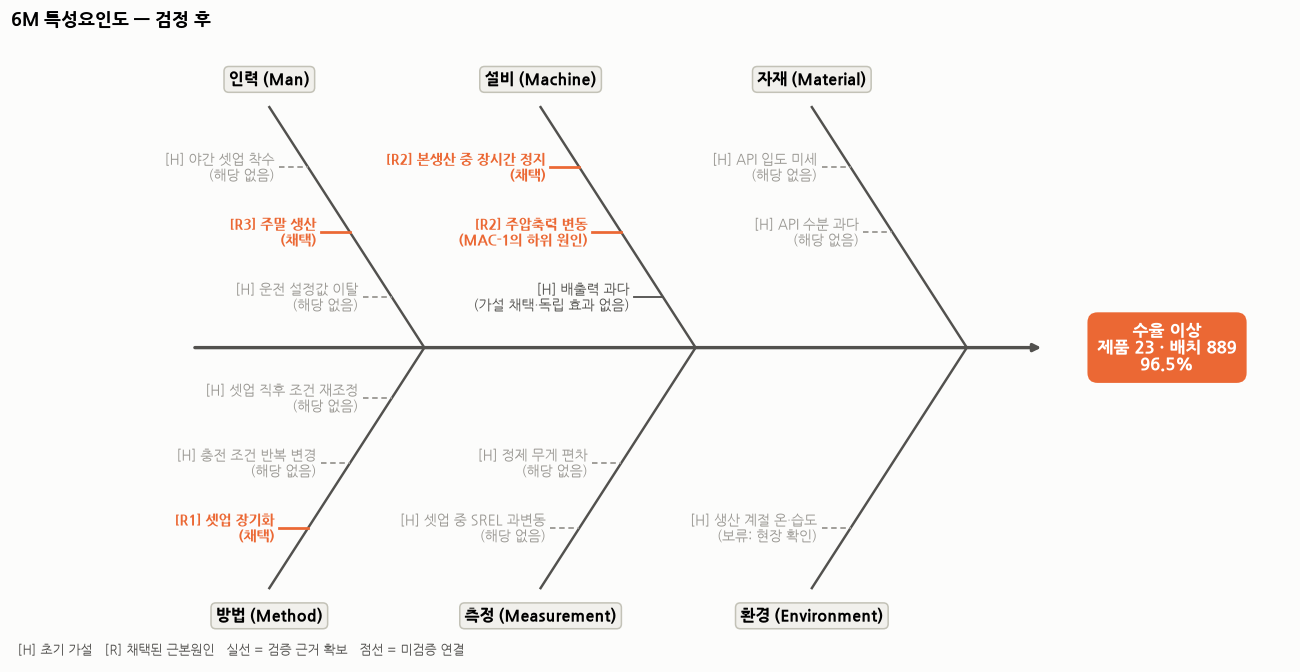

In [13]:
ctx.draw_fishbone(after=True)

### 7.3 근본원인 조사 보고서 (RCA)

In [14]:
ctx.show_rca_report()

### 7.4 결론

In [15]:
ctx.show_conclusion()

> **결론** — 배치 889(제품 23)는 수율 96.50%로 **수율 이상(경고)**입니다.
>
> 데이터로 지지되는 근본원인은 **R1 [방법]** 제품별로 검증된 초기 셋업 설정값(충전 깊이·압축력 레시피)이 정립되어 있지 않다., **R2 [설비]** 재시작 후 공정 조건 안정화 확인 절차와 압축부 상태 점검·경보 기준이 없다., **R3 [인력]** 야간·주말 셋업과 이상 대응에 숙련자 배치·지원 요청(에스컬레이션) 기준이 없다.
>
> 채택 근본원인이 작용한 폐기를 제품 중앙값 수준으로 되돌리면 수율은 약 97.16%(정상)로 추정됩니다.
>
> **현장 확인이 필요한 후보**: RC-ENV(환경) — 대리 지표(계절)만으로는 판단할 수 없음 → 작업장 온·습도 기록 확인.
>
> 손실의 40%만 타정기 기록으로 추적되어, 결론은 기록된 손실에 한정됩니다.
>
> 근본원인의 Why 2~5 중 [추정] 단계는 SOP·셋업 기록·설정 변경 이력·정비 이력으로 확인해야 합니다.